# Linear Regression Lab (SciKit-Learn) — Salary Dataset
## Student Notebook (Fill in the Blanks)

This notebook is available in the codebase that comes along with the book. In this exercise, you will learn how to implement Linear Regression using Scikit-learn, how to build a Machine Learning regression model, and how to draw relevant plots.

**Dataset:** Salary dataset from the codebase (example: `Salary_Data.csv`).

Follow the step-by-step instructions and complete each cell.

## Step 1 — Import Required Libraries
**Task:** Complete the imports.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## Step 2 — Load the Salary Dataset
**Task:** Read the CSV file from the codebase and display top rows.

In [2]:
df = pd.read_csv("../data/cars-retail-price.csv")   # e.g., "Salary_Data.csv"
df.head()

,Vehicle Name,Retail Price,Engine Size,Cylinders,Horsepower,City MPG,Highway MPG,Weight,Wheel Base,Length,Width
0,Chevrolet Aveo 4dr,11690,1.6,4,103,28,34,2370,98,167,66
1,Chevrolet Aveo LS 4dr hatch,12585,1.6,4,103,28,34,2348,98,153,66
2,Chevrolet Cavalier 2dr,14610,2.2,4,140,26,37,2617,104,183,69
3,Chevrolet Cavalier 4dr,14810,2.2,4,140,26,37,2676,104,183,68
4,Chevrolet Cavalier LS 2dr,16385,2.2,4,140,26,37,2617,104,183,69


## Step 3 — Explore the Dataset
**Task:** Print shape, columns, missing values, and statistics.

In [3]:
print("Shape:", df.shape)

print("\nColumns:", df.columns.tolist())

print("\nMissing values:\n", df.isnull().sum())

df.describe()

Shape: (234, 11)

Columns: ['Vehicle Name', 'Retail Price', 'Engine Size', 'Cylinders', 'Horsepower', 'City MPG', 'Highway MPG', 'Weight', 'Wheel Base', 'Length', 'Width']

Missing values:
 Vehicle Name    0
Retail Price    0
Engine Size     0
Cylinders       0
Horsepower      0
City MPG        0
Highway MPG     0
Weight          0
Wheel Base      0
Length          0
Width           0
dtype: int64


,Retail Price,Engine Size,Cylinders,Horsepower,City MPG,Highway MPG,Weight,Wheel Base,Length,Width
count,234.000000,234.000000,234.000000,234.000000,234.000000,234.000000,234.000000,234.000000,234.000000,234.000000
mean,29756.858974,2.899145,5.517094,199.799145,21.799145,29.397436,3313.235043,107.115385,185.927350,70.405983
std,15885.072302,0.925462,1.471374,64.034244,5.732057,5.372014,527.008050,5.822070,12.961111,2.912480
min,10280.000000,1.400000,3.000000,73.000000,13.000000,19.000000,1850.000000,93.000000,143.000000,64.000000
25%,19161.250000,2.200000,4.000000,150.000000,18.000000,26.000000,2937.000000,104.000000,178.000000,68.000000
50%,26007.500000,2.850000,6.000000,200.000000,20.000000,28.000000,3387.500000,107.000000,186.000000,70.000000
75%,36831.250000,3.500000,6.000000,232.000000,24.000000,31.000000,3649.750000,111.000000,194.000000,72.000000
max,128420.000000,5.500000,12.000000,493.000000,60.000000,66.000000,4474.000000,124.000000,221.000000,78.000000


## Step 4 — Define Features (X) and Target (y)
**Task:** Use `YearsExperience` as X and `Salary` as y. Remember: X must be 2D.

In [4]:
X = df[[ "Horsepower" ]]     # Feature matrix (2D)
y = df["Retail Price"]           # Target variable (1D)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (234, 1)
y shape: (234,)


## Step 5 — Split Dataset into Training and Test Sets
**Task:** Use `train_test_split` with a test size and random state.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape, "X_test:", X_test.shape)

X_train: (187, 1) X_test: (47, 1)


## Step 6 — Train the Linear Regression Model
**Task:** Create and fit the model. Print intercept and coefficient.

In [6]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: -13469.47858319699
Coefficient: 217.25805082835015


## Step 7 — Make Predictions
**Task:** Predict salary for the test set and display first 5 rows of results.

In [7]:
y_pred = model.predict(X_test)

pd.DataFrame({
    "Horsepower": X_test["Horsepower"].values,
    "ActualPrice": y_test.values,
    "PredictedPrice": y_pred
}).head()

,Horsepower,ActualPrice,PredictedPrice
0,170,18435,23464.390058
1,235,43895,37586.163361
2,190,33180,27809.551074
3,130,15460,14774.068024
4,265,29440,44103.904886


## Step 8 — Evaluate the Model
**Task:** Compute MAE, MSE, RMSE, and R².

In [8]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R^2 :", r2)

MAE : 6549.738275251084
MSE : 76843292.79936007
RMSE: 8766.030618207997
R^2 : 0.6835140294853627


# Visualization Section

## Step 9 — Scatter Plot of Actual Data
**Task:** Create a scatter plot of YearsExperience vs Salary.

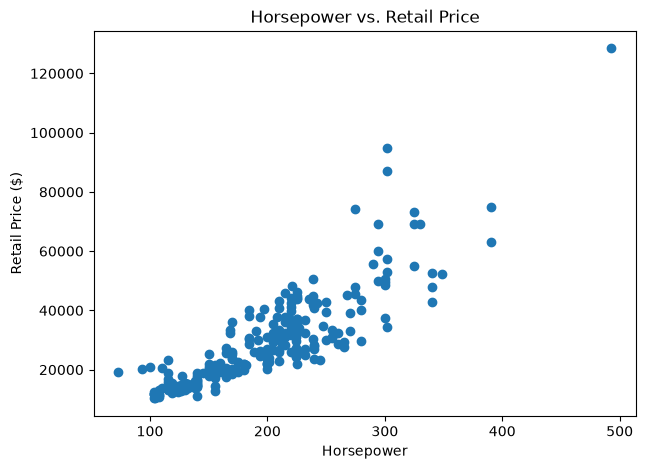

In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(df["Horsepower"], df["Retail Price"])
plt.title("Horsepower vs. Retail Price")
plt.xlabel("Horsepower")
plt.ylabel("Retail Price ($)")
plt.show()

## Step 10 — Plot Regression Line (Train Set)
**Task:** Plot training points and regression line.

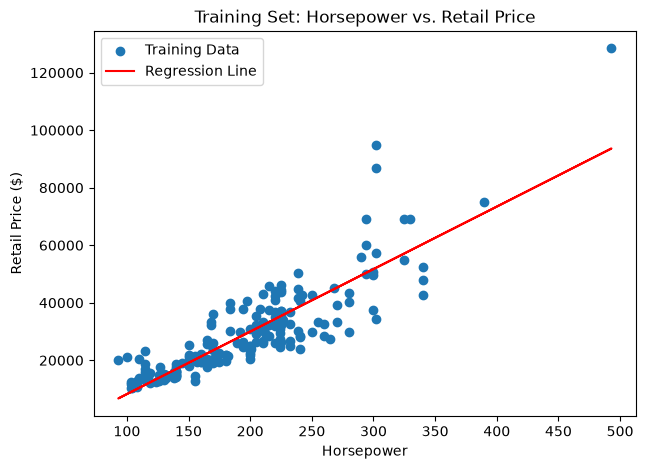

In [10]:
plt.figure(figsize=(7, 5))
plt.scatter(X_train["Horsepower"], y_train, label="Training Data")

y_train_line = model.predict(X_train)
plt.plot(X_train["Horsepower"], y_train_line, label="Regression Line", color="red")

plt.title("Training Set: Horsepower vs. Retail Price")
plt.xlabel("Horsepower")
plt.ylabel("Retail Price ($)")
plt.legend()
plt.show()

## Step 11 — Plot Regression Line (Test Set)
**Task:** Plot test points and regression line (sorted X for a clean line).

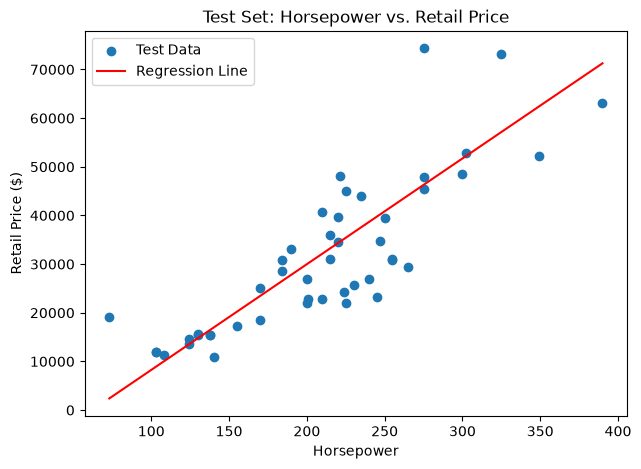

In [11]:
plt.figure(figsize=(7, 5))
plt.scatter(X_test["Horsepower"], y_test, label="Test Data")

X_line = X_test.sort_values(by="Horsepower")
y_line = model.predict(X_line)

plt.plot(X_line["Horsepower"], y_line, label="Regression Line", color="red")

plt.title("Test Set: Horsepower vs. Retail Price")
plt.xlabel("Horsepower")
plt.ylabel("Retail Price ($)")
plt.legend()
plt.show()

## Step 12 — Residual Plot (Optional)
**Task:** Compute residuals and plot residuals vs predicted values.

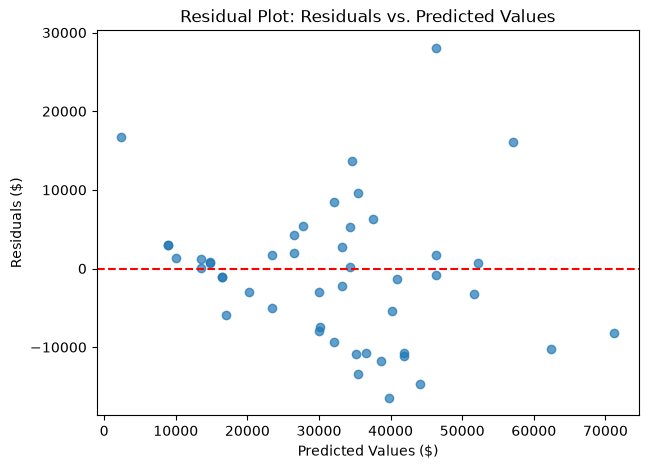

In [12]:
residuals = y_test - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residual Plot: Residuals vs. Predicted Values")
plt.xlabel("Predicted Values ($)")
plt.ylabel("Residuals ($)")
plt.show()

# Mini Exercises (Write Your Answers)
**Exercise A:** What does the slope represent in this dataset?

**Exercise B:** If the model has a high R², what does it indicate?

**Exercise C:** How can outliers affect the regression line?


In [13]:
# Exercise A:
# The slope represents the estimated change in a car's retail price for each additional unit of horsepower.
# For every 1-unit increase in Horsepower, a vehicle's predicted retail price increases by approximately $217.26.


# Exercise B:
# Because R^2 ranges between 0 and 1 (or 0% to 100%), a higher value closer to 1 indicates better model fit and lower residuals, 
# meaning the model explains a larger proportion of the variance in the target variable. 
# Conversely, a lower R^2 value suggests that the model does not fit the data well and may not be a reliable predictor of retail price based on horsepower.
# For this Cars Retail Price model, an R^2 of ~0.6835 meant that horsepower alone accounted for 68.35% of the total price variation across the vehicles.

# Exercise C:
# Outliers severely distort the linear regression line because Ordinary Least Squares (OLS) 
# minimizes the sum of squared residuals. Outliers, which are data points that deviate significantly from the overall trend, 
# can disproportionately influence the slope and intercept of the regression line. 
# This can lead to a model that does not accurately represent the majority of the data, resulting in poor predictions and misleading interpretations.

# Extension Challenge (Optional)
1. Change the test size (example: 0.2 → 0.3)
2. Retrain the model and compare evaluation metrics
3. Write your conclusion in 2–3 lines


In [14]:
# 1. Split with test_size = 0.3
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 2a. Retrain the model with the new training set
model = LinearRegression()
model.fit(X_train, y_train)

# 2b. Generate predictions & compare metrics
y_pred = model.predict(X_test)

original_mae = 6549.738275251084
original_mse = 76843292.79936007
original_rmse = 8766.030618207997
original_r2 = 0.6835140294853627

new_mae = mean_absolute_error(y_test, y_pred)
new_mse = mean_squared_error(y_test, y_pred)
new_rmse = np.sqrt(new_mse)
new_r2 = r2_score(y_test, y_pred)

print("MAE :", new_mae)
print("MSE :", new_mse)
print("RMSE:", new_rmse)
print("R^2 :", new_r2)


# table comparing the metrics from the original model (test_size=0.2) and the new model (test_size=0.3)
metrics_table = {
    "Original (test_size=0.2)": [original_mae, original_mse, original_rmse, original_r2],
    "New (test_size=0.3)": [new_mae, new_mse, new_rmse, new_r2]
}
data = pd.DataFrame(metrics_table, index=["MAE", "MSE", "RMSE", "R^2"])

# print the comparison table with formatting for better readability
print("\nComparison of Metrics:")
print(data.to_string(float_format="{:,.4f}".format))

# 3. Conclusion in 2 - 3 lines
# The change in test size from 0.2 to 0.3 resulted in a slight decrease in model performance, as indicated by the lower R^2 value and higher error metrics.
# This suggests that the model's ability to explain the variance in retail price based on horsepower is somewhat sensitive to the size of the test set, highlighting the importance of careful data splitting in model evaluation.

MAE : 6563.543290029899
MSE : 90063908.22217025
RMSE: 9490.200641828931
R^2 : 0.6320427929015975

Comparison of Metrics:
      Original (test_size=0.2)  New (test_size=0.3)
MAE                 6,549.7383           6,563.5433
MSE            76,843,292.7994      90,063,908.2222
RMSE                8,766.0306           9,490.2006
R^2                     0.6835               0.6320
